In [1]:
import pandas as pd

file_path = r"C:\Users\samka\Downloads\archive (1).zip"
df = pd.read_csv(file_path)

print("Dataset size:", df.shape)
display(df.head())
df.info()

Dataset size: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  str    
 1   Store ID            73100 non-null  str    
 2   Product ID          73100 non-null  str    
 3   Category            73100 non-null  str    
 4   Region              73100 non-null  str    
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  str    
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  str    
dtypes: float64(3), int64(5), str(7)
memory usage: 11.4 MB


In [2]:
print("Columns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nMissing values per column:")
print(df.isna().sum())

Columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']

Date range:
2022-01-01 to 2024-01-01

Missing values per column:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64


In [3]:
# Convert Date from text to a date type
df["Date"] = pd.to_datetime(df["Date"])

# Summaries of numeric columns
display(df.describe().T.round(2))

# Number of records in each category
for column in ["Category", "Region", "Weather Condition", "Seasonality"]:
    print(f"\n{column}:")
    print(df[column].value_counts())

,count,mean,min,25%,50%,75%,max,std
Date,73100,2023-01-01 00:00:00,2022-01-01 00:00:00,2022-07-02 00:00:00,2023-01-01 00:00:00,2023-07-03 00:00:00,2024-01-01 00:00:00,NaN
Inventory Level,73100.0,274.469877,50.0,162.0,273.0,387.0,500.0,129.949514
Units Sold,73100.0,136.46487,0.0,49.0,107.0,203.0,499.0,108.919406
Units Ordered,73100.0,110.004473,20.0,65.0,110.0,155.0,200.0,52.277448
Demand Forecast,73100.0,141.49472,-9.99,53.67,113.015,208.0525,518.55,109.254076
Price,73100.0,55.135108,10.0,32.65,55.05,77.86,100.0,26.021945
Discount,73100.0,10.009508,0.0,5.0,10.0,15.0,20.0,7.083746
Holiday/Promotion,73100.0,0.497305,0.0,0.0,0.0,1.0,1.0,0.499996
Competitor Pricing,73100.0,55.146077,5.03,32.68,55.01,77.82,104.94,26.191408



Category:
Category
Furniture      14699
Toys           14643
Clothing       14626
Groceries      14611
Electronics    14521
Name: count, dtype: int64

Region:
Region
East     18349
South    18297
North    18228
West     18226
Name: count, dtype: int64

Weather Condition:
Weather Condition
Sunny     18290
Rainy     18278
Snowy     18272
Cloudy    18260
Name: count, dtype: int64

Seasonality:
Seasonality
Spring    18317
Summer    18305
Winter    18285
Autumn    18193
Name: count, dtype: int64


In [4]:
# Topic 1 Measure of central tendecy and dispersion - Using unit sold

sales = df["Units Sold"]

print("Mean:", sales.mean())
print("Median:", sales.median())
print("Mode(s):", sales.mode().tolist())
print("Variance:", sales.var())          # sample variance
print("Standard deviation:", sales.std()) # sample standard deviation
print("Minimum:", sales.min())
print("Q1:", sales.quantile(0.25))
print("Q3:", sales.quantile(0.75))
print("Maximum:", sales.max())
print("IQR:", sales.quantile(0.75) - sales.quantile(0.25))

Mean: 136.46487004103966
Median: 107.0
Mode(s): [40]
Variance: 11863.437048198544
Standard deviation: 108.91940620568285
Minimum: 0
Q1: 49.0
Q3: 203.0
Maximum: 499
IQR: 154.0


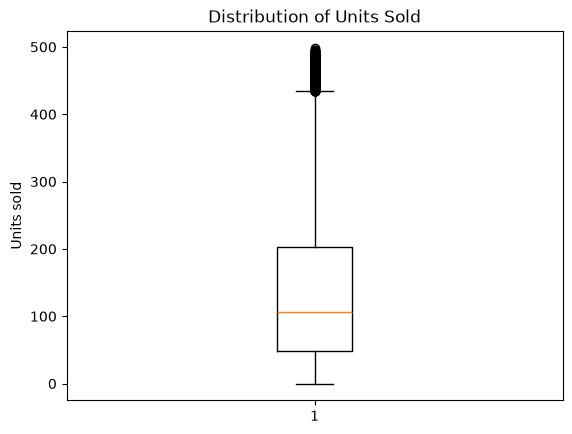

In [5]:
#Making the box plot
import matplotlib.pyplot as plt

plt.boxplot(sales)
plt.title("Distribution of Units Sold")
plt.ylabel("Units sold")
plt.ylabel("Distribution  of Units Sold")
plt.ylabel("Units sold")
plt.show() 

In [7]:
# Units sold averaged about 136.46, with a median of 107. 
#The first and third quartiles were 49 and 203, so the middle half of the records fell between those values.
#The mean being higher than the median suggests that some larger sales values may be pulling the average upward.


In [9]:
# Topic 2: probability and conditional probability. We’ll define a “high sales” record as one where Units Sold is above the overall median.

# Define the events
high_sales = df["Units Sold"] > df["Units Sold"].median()
promotion = df["Holiday/Promotion"] == 1

# Basic and conditional probabilities
p_high = high_sales.mean()
p_promotion = promotion.mean()
p_high_given_promotion = high_sales[promotion].mean()
p_promotion_given_high = promotion[high_sales].mean()

print(f"P(high sales) = {p_high:.3f}")
print(f"P(promotion) = {p_promotion:.3f}")
print(f"P(high sales | promotion) = {p_high_given_promotion:.3f}")
print(f"P(promotion | high sales) = {p_promotion_given_high:.3f}")

P(high sales) = 0.500
P(promotion) = 0.497
P(high sales | promotion) = 0.501
P(promotion | high sales) = 0.498


In [10]:
#in the above P(high sales | promotion means the share of promotion records that had high sales.



In [11]:
# Topic 3: probability distributions. 
# We’ll look at how daily sales totals vary, then compare their distribution to a normal curve. First, create one total per date.
daily_sales = df.groupby("Date")["Units Sold"].sum()

print("Number of dates:", len(daily_sales))
print("Average daily sales:",round(daily_sales.mean(), 2))
print("Daily sales standard deviation:", round(daily_sales.std(), 2))

Number of dates: 731
Average daily sales: 13646.49
Daily sales standard deviation: 1031.96


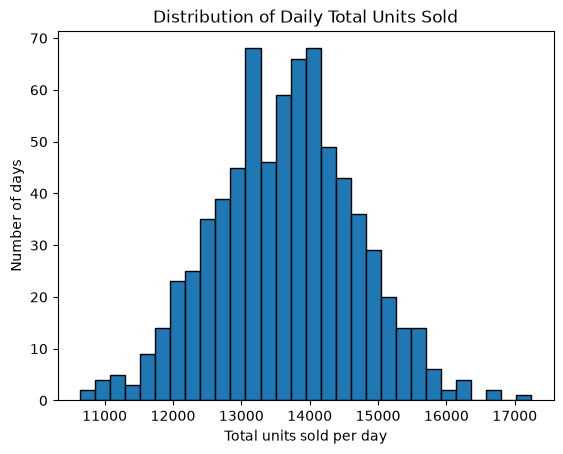

In [12]:
# Plotting the distribution tests.
import matplotlib.pyplot as plt

plt.hist(daily_sales, bins=30, edgecolor="black")
plt.title("Distribution of Daily Total Units Sold")
plt.xlabel("Total units sold per day")
plt.ylabel("Number of days")
plt.show()

In [15]:
# Here we change the unit of analysis from an individual store-product row to a day. We’ll use that daily total for topics like distributions and time-series analysis.
 # in the above cell

Mean of daily sales: 13646.49
Mean of sample means: 13649.39
Observed standard deviation of sample means: 185.67
Estimated standard error: 188.41


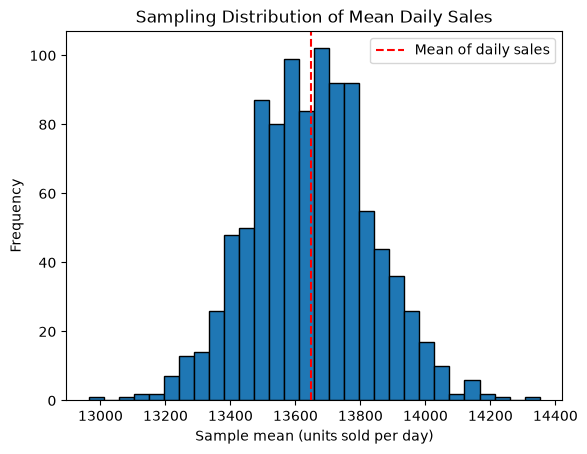

In [16]:
# Topic 4: sampling distributions and the Central Limit Theorem.

#The Central Limit Theorem says that, for sufficiently large samples, the distribution of sample means tends to be approximately normal. Its center is near the population mean, and its standard error is approximately \(\sigma / \sqrt{n}\).

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

sample_size = 30
number_of_samples = 1000

sample_means = [
    np.random.choice(daily_sales, size=sample_size, replace=True).mean()
    for _ in range(number_of_samples)
]

estimated_se = daily_sales.std() / np.sqrt(sample_size)

print("Mean of daily sales:", round(daily_sales.mean(), 2))
print("Mean of sample means:", round(np.mean(sample_means), 2))
print("Observed standard deviation of sample means:", round(np.std(sample_means), 2))
print("Estimated standard error:", round(estimated_se, 2))

plt.hist(sample_means, bins=30, edgecolor="black")
plt.axvline(daily_sales.mean(), color="red", linestyle="--",
            label="Mean of daily sales")
plt.title("Sampling Distribution of Mean Daily Sales")
plt.xlabel("Sample mean (units sold per day)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [17]:
# In the histogram we get to see mean from the repeated samples.


In [18]:
# Confidence interval
# estimation of 95% confidence interval for mean daily total sales.
# using daily_sales

from scipy import stats
import numpy as np

sales = daily_sales.to_numpy()
ci = stats.t.interval(
    confidence=0.95,
    df=len(sales) - 1,
    loc=np.mean(sales),
    scale=stats.sem(sales)
)

print("Mean daily sales:", round(np.mean(sales), 2))
print("95% confidence interval:", tuple(round(v, 2) for v in ci))


Mean daily sales: 13646.49
95% confidence interval: (np.float64(13571.55), np.float64(13721.42))


In [21]:
# topic 6 Hypothesis test
 # Here we are testing whether mean daily_sales differ from 13500 units 
# Treating 13500 as {an illustrative benchmark}

test = stats.ttest_1samp(sales, popmean=13500)

print("t-statistic:", round(test.statistic, 3))
print("p-value:", test.pvalue)


t-statistic: 3.838
p-value: 0.00013483345438965194


In [20]:
# For a 5% significance level , comparing p-value with 0.05.
#a small p-value is evidence that the mean differs from the bechmark

In [22]:
# topic 7 Correlation and covariance
#Correlations range from −1 to 1. 
# where Correlation describes association, not cause and effect.
columns = [
    "Inventory Level", "Units Sold", "Units Ordered",
    "Demand Forecast", "Price", "Discount", "Competitor Pricing"
]

print("Correlation matrix:")
display(df[columns].corr().round(2))

print("Covariance matrix:")
display(df[columns].cov().round(2))

Correlation matrix:


,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Competitor Pricing
Inventory Level,1.00,0.59,0.0,0.59,0.01,0.0,0.01
Units Sold,0.59,1.00,-0.0,1.00,0.00,0.0,0.00
Units Ordered,0.00,-0.00,1.0,-0.00,0.00,-0.0,0.00
Demand Forecast,0.59,1.00,-0.0,1.00,0.00,0.0,0.00
Price,0.01,0.00,0.0,0.00,1.00,0.0,0.99
Discount,0.00,0.00,-0.0,0.00,0.00,1.0,0.00
Competitor Pricing,0.01,0.00,0.0,0.00,0.99,0.0,1.00


Covariance matrix:


,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Competitor Pricing
Inventory Level,16886.88,8350.80,7.20,8356.10,30.91,4.50,31.88
Units Sold,8350.80,11863.44,-5.29,11862.44,3.07,1.99,3.59
Units Ordered,7.20,-5.29,2732.93,-6.29,5.73,-0.35,6.29
Demand Forecast,8356.10,11862.44,-6.29,11936.45,1.92,1.81,2.42
Price,30.91,3.07,5.73,1.92,677.14,0.28,677.39
Discount,4.50,1.99,-0.35,1.81,0.28,50.18,0.36
Competitor Pricing,31.88,3.59,6.29,2.42,677.39,0.36,685.99


In [23]:
#Topic Linear regression
import statsmodels.formula.api as smf

model_df = df.rename(columns={
    "Units Sold": "Units_Sold",
    "Inventory Level": "Inventory_Level",
    "Holiday/Promotion": "Holiday_Promotion"
})

model = smf.ols(
    "Units_Sold ~ Price + Discount + Inventory_Level "
    "+ Holiday_Promotion + C(Category)",
    data=model_df
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Units_Sold   R-squared:                       0.348
Model:                            OLS   Adj. R-squared:                  0.348
Method:                 Least Squares   F-statistic:                     4879.
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:07:29   Log-Likelihood:            -4.3097e+05
No. Observations:               73100   AIC:                         8.620e+05
Df Residuals:                   73091   BIC:                         8.620e+05
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [24]:
# In the output, we see  the coefficients,
# p-values, and R-squared. 
# and Interpret coefficients as associations in this dataset, not proof that a variable causes sales to change.


In [25]:
# Topic 9 Matrix algebra

A = np.array([[4, 2], [1, 3]])
B = np.array([[2, 0], [5, 1]])

print("A + B:\n", A + B)
print("A multiplied by B:\n", A @ B)
print("Transpose of A:\n", A.T)
print("Determinant of A:", np.linalg.det(A))
print("Inverse of A:\n", np.linalg.inv(A))

b = np.array([10, 8])
print("Solution to A x = b:", np.linalg.solve(A, b))

A + B:
 [[6 2]
 [6 4]]
A multiplied by B:
 [[18  2]
 [17  3]]
Transpose of A:
 [[4 1]
 [2 3]]
Determinant of A: 10.000000000000002
Inverse of A:
 [[ 0.3 -0.2]
 [-0.1  0.4]]
Solution to A x = b: [1.4 2.2]


Variance explained by each component: [0.353 0.285]
Total variance explained: 0.638


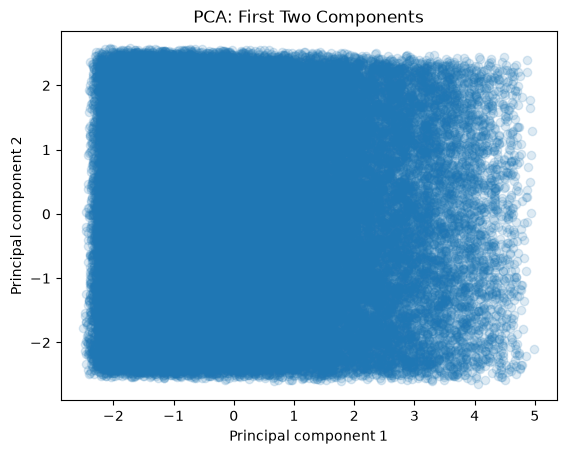

In [26]:
#Topic 10 PCA 
# Where PCA summarizes several numeric variables into a smaller number of components.
# Like standardizing them first because they use different scales.

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

features = [
    "Inventory Level", "Units Sold", "Units Ordered",
    "Demand Forecast", "Price", "Discount", "Competitor Pricing"
]

X = StandardScaler().fit_transform(df[features])
pca = PCA(n_components=2)
components = pca.fit_transform(X)

print("Variance explained by each component:",
      pca.explained_variance_ratio_.round(3))
print("Total variance explained:",
      round(pca.explained_variance_ratio_.sum(), 3))

plt.scatter(components[:, 0], components[:, 1], alpha=0.15)
plt.title("PCA: First Two Components")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.show()

In [27]:
# topic 11 . Numerical optimization
# here we do the fitting of a normal curve to daily_sales by estimation.
# checking the mean and standard deviation thru maximum likelihood.

from scipy.optimize import minimize
import numpy as np

x = daily_sales.to_numpy()

def negative_log_likelihood(params):
    mu, log_sigma = params
    sigma = np.exp(log_sigma)  # keeps standard deviation positive
    return np.sum(np.log(sigma) + ((x - mu) ** 2) / (2 * sigma ** 2))

result = minimize(
    negative_log_likelihood,
    x0=[x.mean(), np.log(x.std())]
)

print("Estimated mean:", round(result.x[0], 2))
print("Estimated standard deviation:", round(np.exp(result.x[1]), 2))
print("Optimization successful:", result.success)
print("Message:", result.message)

Estimated mean: 13646.49
Estimated standard deviation: 1031.25
Optimization successful: True
Message: Optimization terminated successfully.


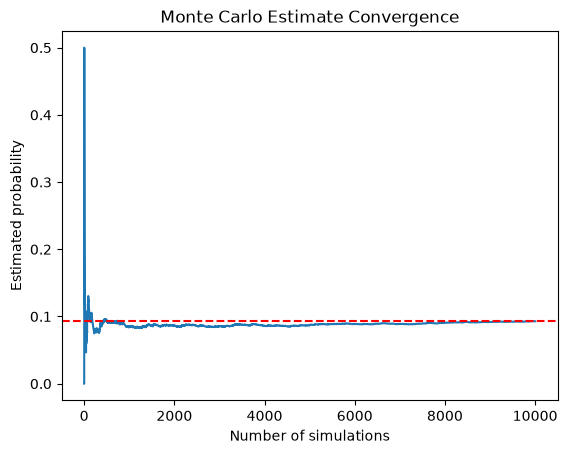

In [41]:
#topic 12 Random numbers and Monte Carlo.
# we are estimating the chance that daily sales exceed 15000 units by repeatedly sampling observed days.
outcomes = (simulated_sales > 15000).astype(int)
running_probability = np.cumsum(outcomes) / np.arange(1, len(outcomes) + 1)

plt.plot(running_probability)
plt.axhline(running_probability[-1], color="red", linestyle="--")
plt.title("Monte Carlo Estimate Convergence")
plt.xlabel("Number of simulations")
plt.ylabel("Estimated probability")
plt.show()

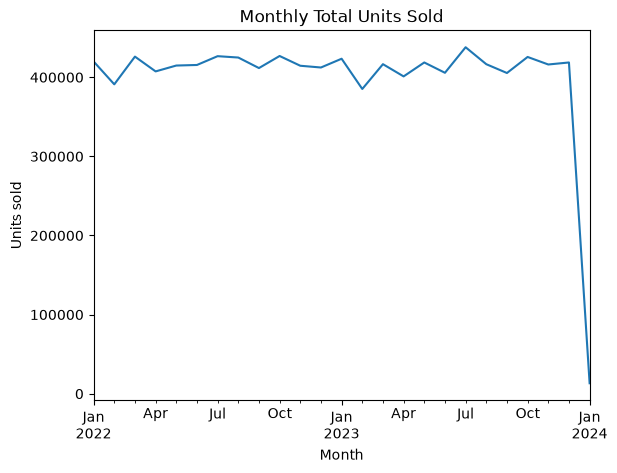

Date
2022-01-01    419938
2022-02-01    391052
2022-03-01    426073
2022-04-01    407380
2022-05-01    414799
Freq: MS, Name: Units Sold, dtype: int64


In [29]:
#topic 13 Time-series analysis
#Aggregating the store and product rows into daily totals, then monthly totals.

import matplotlib.pyplot as plt

monthly_sales = daily_sales.resample("MS").sum()

monthly_sales.plot()
plt.title("Monthly Total Units Sold")
plt.xlabel("Month")
plt.ylabel("Units sold")
plt.show()

print(monthly_sales.head())

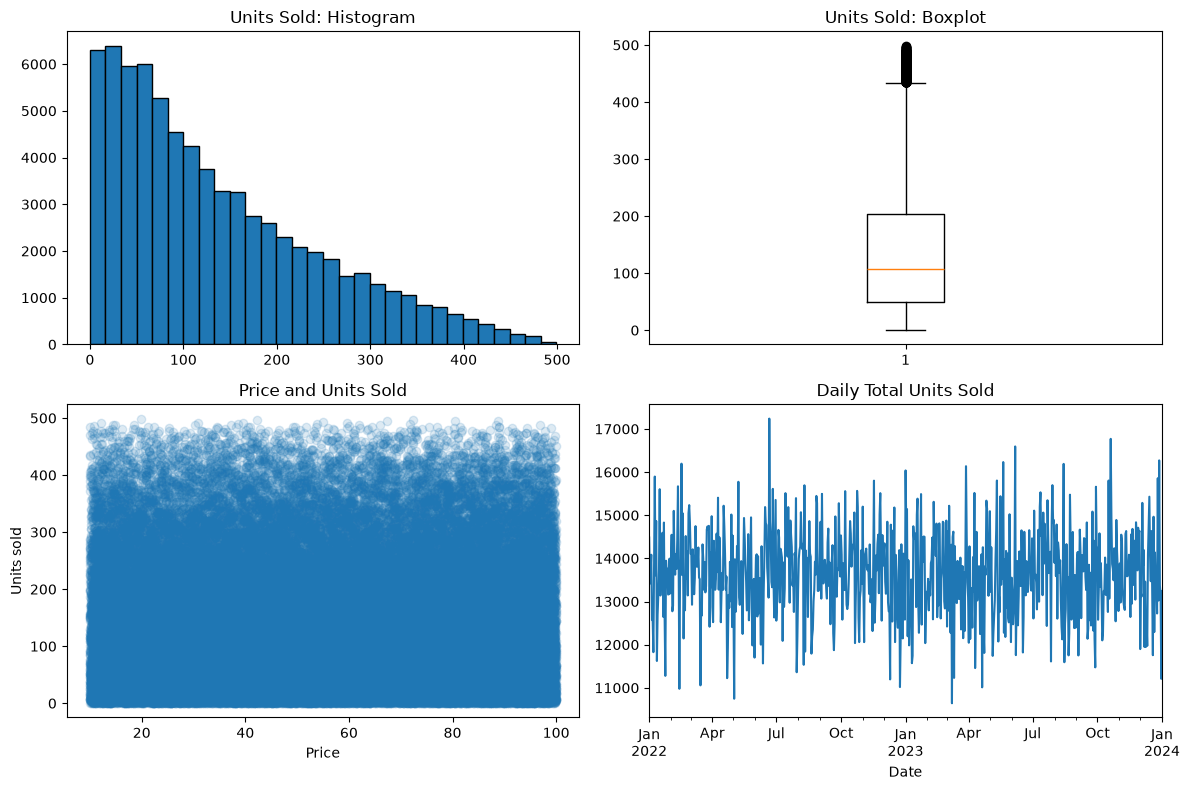

In [30]:
# topic 14 Statistical data visualization
#Create a histogram, boxplot, scatter plot, and time-series line graph.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(df["Units Sold"], bins=30, edgecolor="black")
axes[0, 0].set_title("Units Sold: Histogram")

axes[0, 1].boxplot(df["Units Sold"])
axes[0, 1].set_title("Units Sold: Boxplot")

axes[1, 0].scatter(df["Price"], df["Units Sold"], alpha=0.15)
axes[1, 0].set_title("Price and Units Sold")
axes[1, 0].set_xlabel("Price")
axes[1, 0].set_ylabel("Units sold")

daily_sales.plot(ax=axes[1, 1])
axes[1, 1].set_title("Daily Total Units Sold")

plt.tight_layout()
plt.show()


In [32]:
# topic 15 Data transformation and normalization

#here we are Comparing the standardized and min-max-scaled sales values.
# the Standardized values are centered around zero; min-max values range from 0 to 1.
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sales_values = df[["Units Sold"]]

df["Sales Standardized"] = StandardScaler().fit_transform(sales_values)
df["Sales MinMax"] = MinMaxScaler().fit_transform(sales_values)

display(df[["Units Sold", "Sales Standardized", "Sales MinMax"]].head())

,Units Sold,Sales Standardized,Sales MinMax
0,127,-0.086899,0.254509
1,150,0.124268,0.300601
2,65,-0.656131,0.130261
3,61,-0.692855,0.122244
4,14,-1.124370,0.028056


In [34]:
# topic 16 ANOVA and experimental design.
# we are Testing whether mean units sold differs across product categories.

#The small p-value suggests that at least one category mean differs. ANOVA alone does not tell you which categories differ.

from scipy import stats

groups = [
    group["Units Sold"].to_numpy()
    for _, group in df.groupby("Category")
]

anova = stats.f_oneway(*groups)

print("F-statistic:", round(anova.statistic, 3))
print("p-value:", anova.pvalue)
print(df.groupby("Category")["Units Sold"].mean().round(2))

F-statistic: 1.339
p-value: 0.2525386553001108
Category
Clothing       136.69
Electronics    135.01
Furniture      137.77
Groceries      136.92
Toys           135.93
Name: Units Sold, dtype: float64


In [43]:
#topic 17 Chi-square and categorical data
#H ere we are Checking whether promotion status and region are associated.

display(pd.DataFrame(expected, index=table.index, columns=table.columns).round(2))

Holiday/Promotion,0,1
Region,,
East,9223.95,9125.05
North,9163.12,9064.88
South,9197.81,9099.19
West,9162.12,9063.88


In [42]:
#  topic 18 Logistic regression
# here we are Defining “high sales” as units sold above the dataset median, then predicting the outcome

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

features = ["Price", "Discount", "Inventory Level", "Holiday/Promotion"]
X = df[features]
y = (df["Units Sold"] > df["Units Sold"].median()).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)
predictions = log_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, predictions))
print(classification_report(y_test, predictions))

#This creates a teaching example of binary classification. “High sales” is a definition we chose, not a label supplied by the dataset.

Confusion matrix:
[[5189 2123]
 [2085 5223]]
              precision    recall  f1-score   support

           0       0.71      0.71      0.71      7312
           1       0.71      0.71      0.71      7308

    accuracy                           0.71     14620
   macro avg       0.71      0.71      0.71     14620
weighted avg       0.71      0.71      0.71     14620



In [37]:
# Topic 19 Non-parametric methods
# here we are Using  the Kruskal-Wallis test to compare sales across categories without assuming normally distributed sales.

groups = [
    group["Units Sold"].to_numpy()
    for _, group in df.groupby("Category")
]

kruskal = stats.kruskal(*groups)

print("Kruskal-Wallis statistic:", round(kruskal.statistic, 3))
print("p-value:", kruskal.pvalue)

Kruskal-Wallis statistic: 4.293
p-value: 0.3678649997419618


In [38]:
#topic 20 Bootstrap and resampling
# here we are Estimating the 95% bootstrap confidence interval for mean daily sales.

np.random.seed(42)

x = daily_sales.to_numpy()
bootstrap_means = [
    np.random.choice(x, size=len(x), replace=True).mean()
    for _ in range(5000)
]

lower, upper = np.percentile(bootstrap_means, [2.5, 97.5])

print("Observed mean daily sales:", round(x.mean(), 2))
print("Bootstrap 95% confidence interval:",
      (round(lower, 2), round(upper, 2)))

Observed mean daily sales: 13646.49
Bootstrap 95% confidence interval: (np.float64(13571.49), np.float64(13722.89))


In [39]:
# topic 21 Multivariate analysis

#Here we  used clustering to group store-product-day records based on numeric measurements.

# where The cluster numbers are just group labels. Use the group averages to describe how the clusters differ.

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = [
    "Inventory Level", "Units Sold", "Units Ordered",
    "Price", "Discount", "Competitor Pricing"
]
X_scaled = StandardScaler().fit_transform(df[features])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df["Cluster"].value_counts().sort_index())
display(df.groupby("Cluster")[features].mean().round(2))

Cluster
0    18403
1    27326
2    27371
Name: count, dtype: int64


,Inventory Level,Units Sold,Units Ordered,Price,Discount,Competitor Pricing
Cluster,,,,,,
0,408.70,279.81,110.18,54.84,10.04,54.86
1,231.40,88.72,110.22,79.17,10.00,79.29
2,227.22,87.75,109.67,31.34,10.00,31.23


In [40]:
#TOPIC 22 Missing-data analysis
# The data am using has no actual missing values i downloaded it on kaggle.
 # in this example we will see the example temporarily hides 5% of Units Sold values to demonstrate median imputation.

sales_with_missing = df["Units Sold"].astype(float).copy()

rng = np.random.default_rng(42)
missing_rows = rng.choice(
    sales_with_missing.index,
    size=int(0.05 * len(sales_with_missing)),
    replace=False
)
sales_with_missing.loc[missing_rows] = np.nan

imputed_sales = sales_with_missing.fillna(sales_with_missing.median())

print("Simulated missing values:", sales_with_missing.isna().sum())
print("Original mean:", round(df["Units Sold"].mean(), 2))
print("Mean after median imputation:", round(imputed_sales.mean(), 2))

Simulated missing values: 3655
Original mean: 136.46
Mean after median imputation: 134.95


In [45]:
 # Topic 23 Statistical reporting and reproducibility

from IPython.display import display, Markdown
from scipy import stats
import numpy as np
import pandas as pd

# Recalculate key results so this report cell is self-contained
daily_totals = df.groupby("Date")["Units Sold"].sum()
daily_array = daily_totals.to_numpy()

daily_ci = stats.t.interval(
    confidence=0.95,
    df=len(daily_array) - 1,
    loc=daily_array.mean(),
    scale=stats.sem(daily_array)
)

benchmark_test = stats.ttest_1samp(daily_array, popmean=13500)

category_groups = [
    group["Units Sold"].to_numpy()
    for _, group in df.groupby("Category")
]
anova_result = stats.f_oneway(*category_groups)
kruskal_result = stats.kruskal(*category_groups)

region_promotion_table = pd.crosstab(df["Region"], df["Holiday/Promotion"])
chi_square, chi_p, chi_dof, expected = stats.chi2_contingency(
    region_promotion_table
)

# THE DATASET SOURCE I USED AND THE LINK.
dataset_source = "Retail Store Inventory Forecasting Dataset, Anirudh Chauhan, https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset"

report = f"""
# Topic 23: Statistical Reporting and Reproducible Analysis

## Aim
This analysis uses the retail store inventory dataset to explore sales,
inventory, pricing, promotions, and patterns over time.

## Dataset
The dataset contains {len(df):,} store-product records, dated from
{df["Date"].min().date()} to {df["Date"].max().date()}. The original file has
15 columns and no missing values.

**Source:** {dataset_source}

Some analyses use an individual store-product record. Time-series analyses
first combine records into daily or monthly sales totals.

## Methods
The notebook demonstrates descriptive statistics, probability, sampling,
confidence intervals, hypothesis testing, correlation, regression, matrix
algebra, PCA, optimization, Monte Carlo simulation, time-series summaries,
visualization, data transformation, ANOVA, chi-square analysis, logistic
regression, non-parametric testing, bootstrap resampling, clustering, and
a simulated missing-data example.

## Key results

- Mean units sold per record: **{df["Units Sold"].mean():.2f}**.
- Mean daily total sales: **{daily_array.mean():,.2f}** units.
- 95% confidence interval for mean daily sales:
  **({daily_ci[0]:,.2f}, {daily_ci[1]:,.2f})**.
- One-sample t-test against the illustrative benchmark of 13,500 units:
  **t = {benchmark_test.statistic:.3f}, p = {benchmark_test.pvalue:.4g}**.
- ANOVA comparing mean units sold across categories:
  **F = {anova_result.statistic:.3f}, p = {anova_result.pvalue:.4g}**.
- Kruskal-Wallis comparison across categories:
  **H = {kruskal_result.statistic:.3f}, p = {kruskal_result.pvalue:.4g}**.
- Chi-square test of region and promotion status:
  **χ² = {chi_square:.3f}, df = {chi_dof}, p = {chi_p:.4g}**.
- The notebook’s regression, PCA, charts, clustering, bootstrap, and
  classification results are shown in their earlier sections.

## Interpretation
The one-sample test compares mean daily sales with an illustrative benchmark;
the benchmark should be justified in the presentation. ANOVA and
Kruskal-Wallis test for category differences, while the chi-square test checks
whether region and promotion status are associated. Interpret p-values using
the chosen significance level, and describe these as evidence of association
or differences rather than proof of cause.

## Limitations
The dataset has no naturally missing values, so the missing-data section
simulates missing entries for demonstration. The Demand Forecast column
contains a negative value, which should be checked before interpreting that
variable. The benchmark of 13,500 units is illustrative unless the group can
justify it. The analyses describe this dataset and do not establish causation.

## Conclusion
The notebook combines code, statistical results, tables, and visualizations
to examine the retail sales data. The final conclusions should be based on
the displayed results and should answer the project aim.

## Reproducibility
The analysis is recorded in this Jupyter notebook. Restart the kernel and run
all cells from top to bottom before sharing it. Include the dataset source
above and confirm whether the instructor expects R code as well as Python.
"""

display(Markdown(report))


# Topic 23: Statistical Reporting and Reproducible Analysis

## Aim
This analysis uses the retail store inventory dataset to explore sales,
inventory, pricing, promotions, and patterns over time.

## Dataset
The dataset contains 73,100 store-product records, dated from
2022-01-01 to 2024-01-01. The original file has
15 columns and no missing values.

**Source:** Retail Store Inventory Forecasting Dataset, Anirudh Chauhan, https://www.kaggle.com/datasets/anirudhchauhan/retail-store-inventory-forecasting-dataset

Some analyses use an individual store-product record. Time-series analyses
first combine records into daily or monthly sales totals.

## Methods
The notebook demonstrates descriptive statistics, probability, sampling,
confidence intervals, hypothesis testing, correlation, regression, matrix
algebra, PCA, optimization, Monte Carlo simulation, time-series summaries,
visualization, data transformation, ANOVA, chi-square analysis, logistic
regression, non-parametric testing, bootstrap resampling, clustering, and
a simulated missing-data example.

## Key results

- Mean units sold per record: **136.46**.
- Mean daily total sales: **13,646.49** units.
- 95% confidence interval for mean daily sales:
  **(13,571.55, 13,721.42)**.
- One-sample t-test against the illustrative benchmark of 13,500 units:
  **t = 3.838, p = 0.0001348**.
- ANOVA comparing mean units sold across categories:
  **F = 1.339, p = 0.2525**.
- Kruskal-Wallis comparison across categories:
  **H = 4.293, p = 0.3679**.
- Chi-square test of region and promotion status:
  **χ² = 1.349, df = 3, p = 0.7174**.
- The notebook’s regression, PCA, charts, clustering, bootstrap, and
  classification results are shown in their earlier sections.

## Interpretation
The one-sample test compares mean daily sales with an illustrative benchmark;
the benchmark should be justified in the presentation. ANOVA and
Kruskal-Wallis test for category differences, while the chi-square test checks
whether region and promotion status are associated. Interpret p-values using
the chosen significance level, and describe these as evidence of association
or differences rather than proof of cause.

## Limitations
The dataset has no naturally missing values, so the missing-data section
simulates missing entries for demonstration. The Demand Forecast column
contains a negative value, which should be checked before interpreting that
variable. The benchmark of 13,500 units is illustrative unless the group can
justify it. The analyses describe this dataset and do not establish causation.

## Conclusion
The notebook combines code, statistical results, tables, and visualizations
to examine the retail sales data. The final conclusions should be based on
the displayed results and should answer the project aim.

## Reproducibility
The analysis is recorded in this Jupyter notebook. Restart the kernel and run
all cells from top to bottom before sharing it. Include the dataset source
above and confirm whether the instructor expects R code as well as Python.


In [46]:
#cat 2